# Model Performance Analysis

This notebook analyzes the performance of models trained with different alpha values and expansion factors across three evaluation datasets: ImageNet-1K, ImageNet-V2, and Blurred ImageNet-1K.

## 1. Import Required Libraries

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better-looking plots
sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load and Explore the Data

In [86]:
# Load the data
df = pd.read_csv('FULL_RESULTS.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (36, 10)

Columns: ['alpha', 'beta', 'lr', 'expansion', 'imagenet_1k accuracy', 'imagenet_1k ECE', 'imagenet_v2 accuracy', 'imagenet_v2 ECE', 'blurred_imagenet_1k accuracy', 'blurred_imagenet_1k ECE']

First few rows:


,alpha,beta,lr,expansion,imagenet_1k accuracy,imagenet_1k ECE,imagenet_v2 accuracy,imagenet_v2 ECE,blurred_imagenet_1k accuracy,blurred_imagenet_1k ECE
0,-1.0,1.0,0.001,2,0.7540,0.065360,0.0120,0.742724,0.6855,0.084125
1,-1.0,1.0,0.001,4,0.7590,0.075434,0.0125,0.757552,0.6995,0.082115
2,-1.0,1.0,0.001,32,0.6545,0.138408,0.0130,0.705802,0.5680,0.151443
3,0.0,1.0,0.001,2,0.0010,0.005796,0.0010,0.005797,0.0010,0.005807
4,0.0,1.0,0.001,4,0.0010,0.007029,0.0010,0.007028,0.0010,0.007044


In [87]:
# Basic statistics
print("Alpha values:", sorted(df['alpha'].unique()))
print("Expansion factors:", sorted(df['expansion'].unique()))
print("\nDataset info:")
df.info()

Alpha values: [-1.0, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Expansion factors: [2, 4, 32]

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alpha                         36 non-null     float64
 1   beta                          36 non-null     float64
 2   lr                            36 non-null     float64
 3   expansion                     36 non-null     int64  
 4   imagenet_1k accuracy          36 non-null     float64
 5   imagenet_1k ECE               36 non-null     float64
 6   imagenet_v2 accuracy          36 non-null     float64
 7   imagenet_v2 ECE               36 non-null     float64
 8   blurred_imagenet_1k accuracy  36 non-null     float64
 9   blurred_imagenet_1k ECE       36 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 2.9 KB


## 3. Data Preprocessing and Grouping

In [88]:
# Separate data by characteristics
df_fixed_alpha = df[df['alpha'] >= 0].copy()  # Fixed alpha values (0 to 1)
df_scheduled = df[df['alpha'] == -1].copy()  # Scheduled alpha
df_baseline = df[df['alpha'] == 1.0].copy()  # Baseline (control)

print(f"Fixed alpha models: {len(df_fixed_alpha)} rows")
print(f"Scheduled alpha models: {len(df_scheduled)} rows")
print(f"Baseline models: {len(df_baseline)} rows")

# Create a label for better visualization
df['alpha_type'] = df['alpha'].apply(lambda x: 'Scheduled' if x == -1 else ('Baseline' if x == 1.0 else 'Fixed'))
df['expansion_label'] = df['expansion'].apply(lambda x: f'Expansion {x}')

Fixed alpha models: 33 rows
Scheduled alpha models: 3 rows
Baseline models: 3 rows


## 4. Accuracy and ECE vs Alpha by Expansion Factor

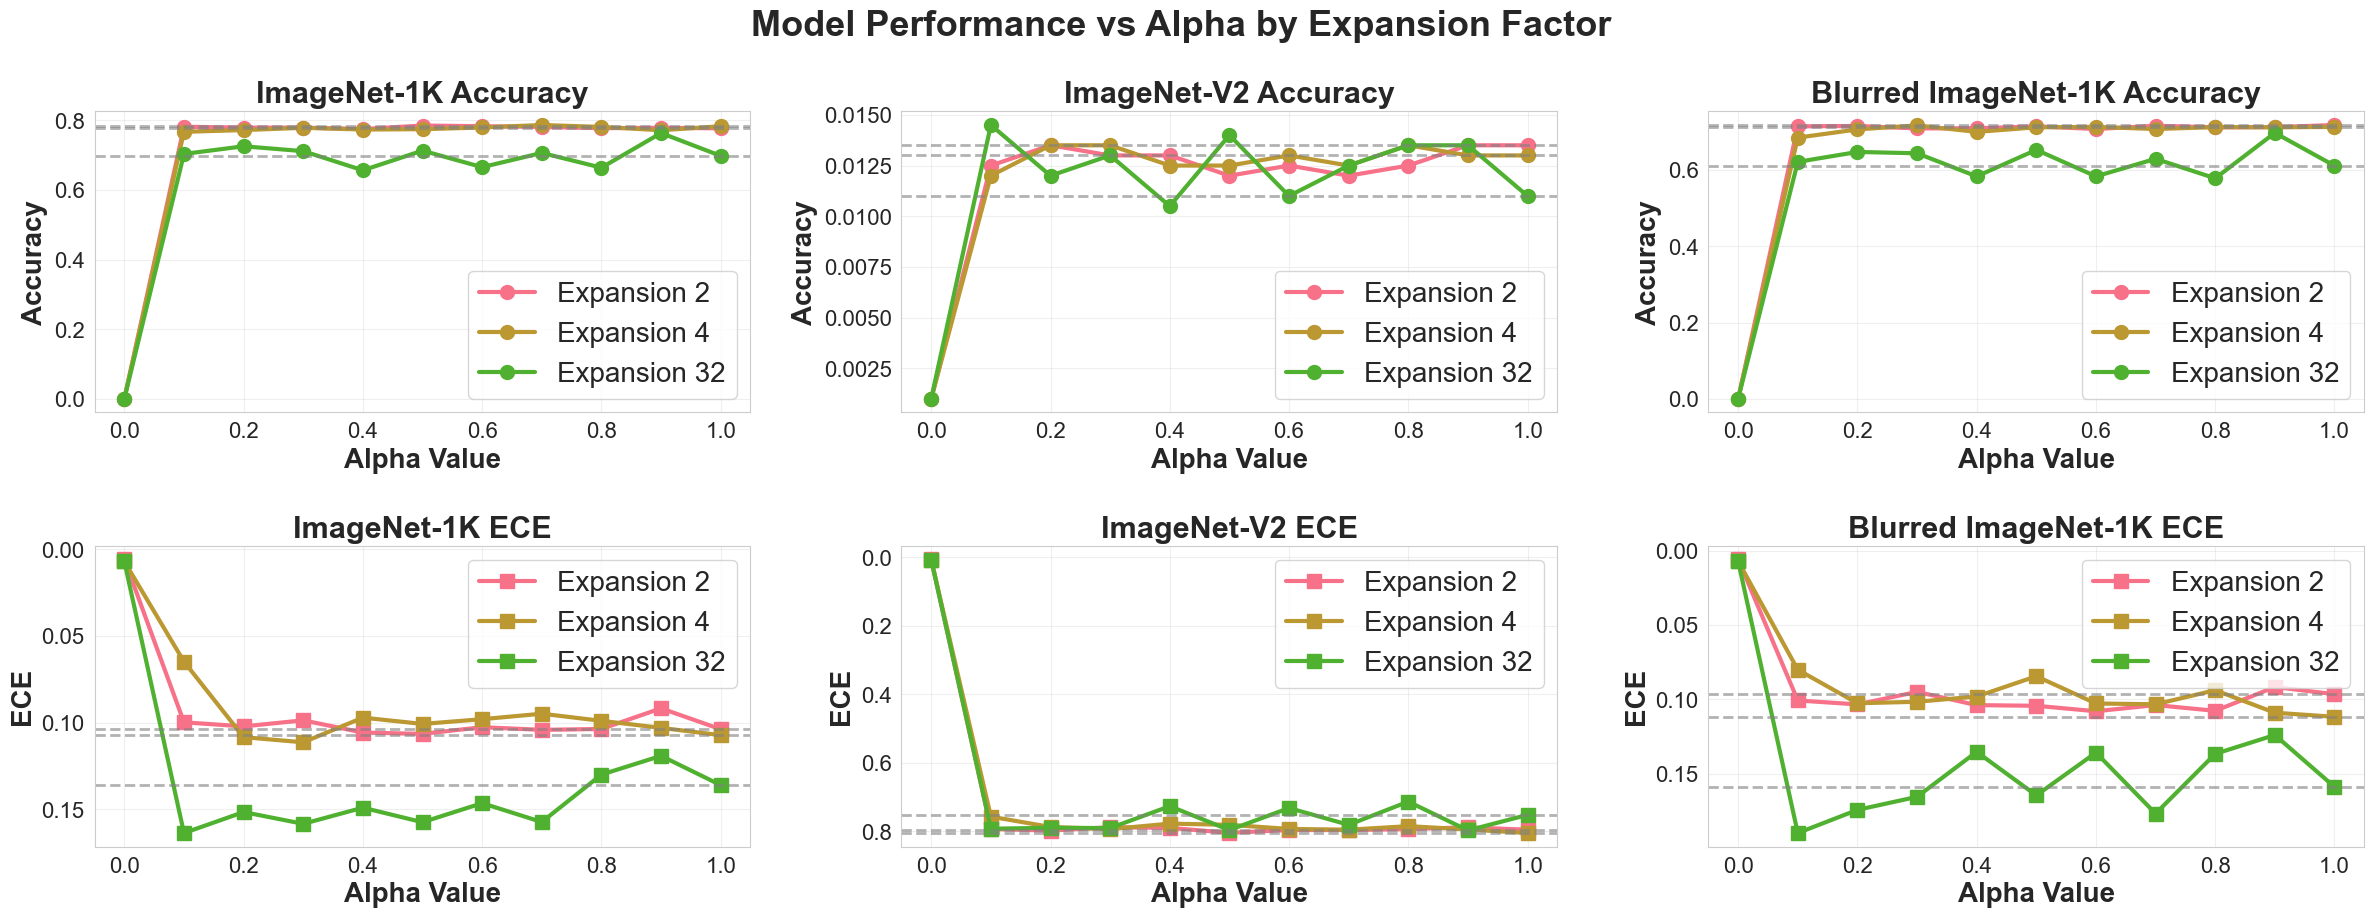

In [89]:
fig, axes = plt.subplots(2, 3, figsize=(24, 10))
datasets = ['imagenet_1k accuracy', 'imagenet_v2 accuracy', 'blurred_imagenet_1k accuracy']
ece_datasets = ['imagenet_1k ECE', 'imagenet_v2 ECE', 'blurred_imagenet_1k ECE']
titles = ['ImageNet-1K', 'ImageNet-V2', 'Blurred ImageNet-1K']

# Font size settings
label_fontsize = 20  # slightly bigger
title_fontsize = 22  # reduced to avoid overlap
legend_fontsize = 20
tick_fontsize = 16

# Top row: Accuracy plots
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    
    # Plot for each expansion factor
    for exp in sorted(df_fixed_alpha['expansion'].unique()):
        data = df_fixed_alpha[df_fixed_alpha['expansion'] == exp]
        ax.plot(data['alpha'], data[dataset], marker='o', linewidth=3, 
                label=f'Expansion {exp}', markersize=10)
    
    # Add baseline reference lines (more visible)
    for exp in sorted(df_baseline['expansion'].unique()):
        baseline_acc = df_baseline[df_baseline['expansion'] == exp][dataset].values[0]
        ax.axhline(y=baseline_acc, linestyle='--', alpha=0.6, linewidth=2, color='gray')
    
    ax.set_xlabel('Alpha Value', fontsize=label_fontsize, fontweight='bold')
    ax.set_ylabel('Accuracy', fontsize=label_fontsize, fontweight='bold')
    ax.set_title(f'{title} Accuracy', fontsize=title_fontsize, fontweight='bold')
    ax.legend(loc='best', fontsize=legend_fontsize)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', labelsize=tick_fontsize)

# Bottom row: ECE plots
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    
    # Plot for each expansion factor
    for exp in sorted(df_fixed_alpha['expansion'].unique()):
        data = df_fixed_alpha[df_fixed_alpha['expansion'] == exp]
        ax.plot(data['alpha'], data[dataset], marker='s', linewidth=3, 
                label=f'Expansion {exp}', markersize=10)
    
    # Add baseline reference lines (more visible)
    for exp in sorted(df_baseline['expansion'].unique()):
        baseline_ece = df_baseline[df_baseline['expansion'] == exp][dataset].values[0]
        ax.axhline(y=baseline_ece, linestyle='--', alpha=0.6, linewidth=2, color='gray')
    
    ax.set_xlabel('Alpha Value', fontsize=label_fontsize, fontweight='bold')
    ax.set_ylabel('ECE', fontsize=label_fontsize, fontweight='bold')
    ax.set_title(f'{title} ECE', fontsize=title_fontsize, fontweight='bold')
    ax.legend(loc='best', fontsize=legend_fontsize)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.invert_yaxis()  # Invert so upward = better (lower ECE)

plt.suptitle('Model Performance vs Alpha by Expansion Factor', fontsize=26, fontweight='bold', y=0.995)

plt.tight_layout(rect=[0, 0.08, 1, 0.99], pad=1.2, w_pad=3, h_pad=3)
plt.show()


## 5. Accuracy Comparison Across Datasets

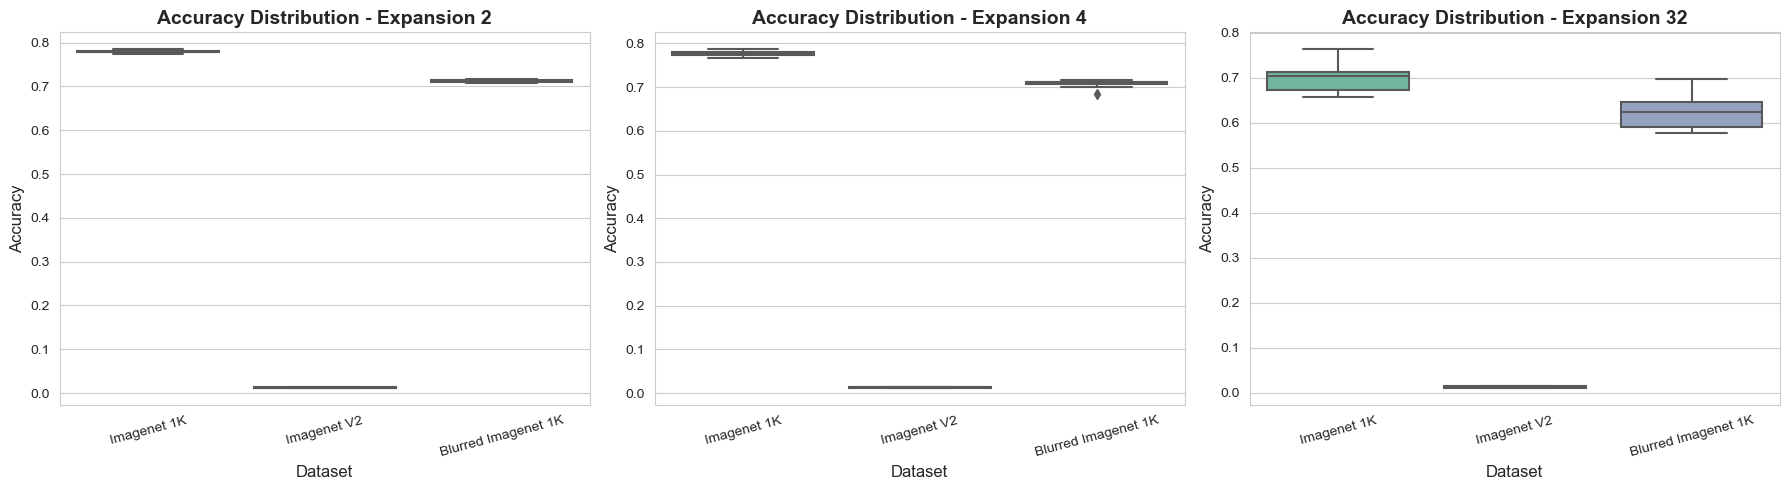

In [7]:
# Reshape data for grouped comparison (excluding alpha=0 which has very low accuracy)
df_plot = df_fixed_alpha[df_fixed_alpha['alpha'] > 0].copy()

# Melt the dataframe for easier plotting
acc_melted = df_plot.melt(
    id_vars=['alpha', 'expansion'], 
    value_vars=['imagenet_1k accuracy', 'imagenet_v2 accuracy', 'blurred_imagenet_1k accuracy'],
    var_name='Dataset', 
    value_name='Accuracy'
)
acc_melted['Dataset'] = acc_melted['Dataset'].str.replace(' accuracy', '').str.replace('_', ' ').str.title()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, exp in enumerate(sorted(df_plot['expansion'].unique())):
    ax = axes[idx]
    data = acc_melted[acc_melted['expansion'] == exp]
    
    sns.boxplot(data=data, x='Dataset', y='Accuracy', ax=ax, palette='Set2')
    ax.set_title(f'Accuracy Distribution - Expansion {exp}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Dataset', fontsize=12)
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.tick_params(axis='x', rotation=15)
    
plt.tight_layout()
plt.show()

## 6. ECE Comparison Across Datasets

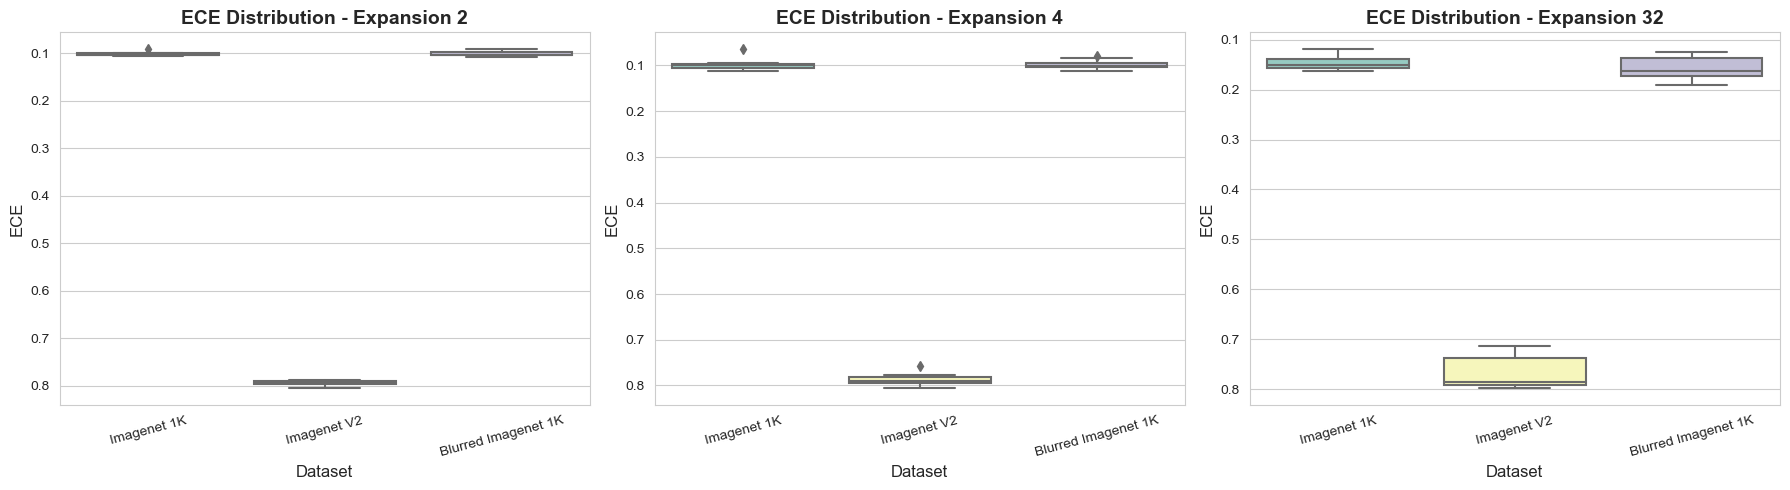

In [39]:
# Melt ECE data for comparison
ece_melted = df_plot.melt(
    id_vars=['alpha', 'expansion'], 
    value_vars=['imagenet_1k ECE', 'imagenet_v2 ECE', 'blurred_imagenet_1k ECE'],
    var_name='Dataset', 
    value_name='ECE'
)
ece_melted['Dataset'] = ece_melted['Dataset'].str.replace(' ECE', '').str.replace('_', ' ').str.title()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, exp in enumerate(sorted(df_plot['expansion'].unique())):
    ax = axes[idx]
    data = ece_melted[ece_melted['expansion'] == exp]
    
    sns.boxplot(data=data, x='Dataset', y='ECE', ax=ax, palette='Set3')
    ax.set_title(f'ECE Distribution - Expansion {exp}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Dataset', fontsize=12)
    ax.set_ylabel('ECE', fontsize=12)
    ax.tick_params(axis='x', rotation=15)
    ax.invert_yaxis()  # Invert so upward = better (lower ECE)
    
plt.tight_layout()
plt.show()

## 7. Accuracy vs ECE Trade-off Analysis

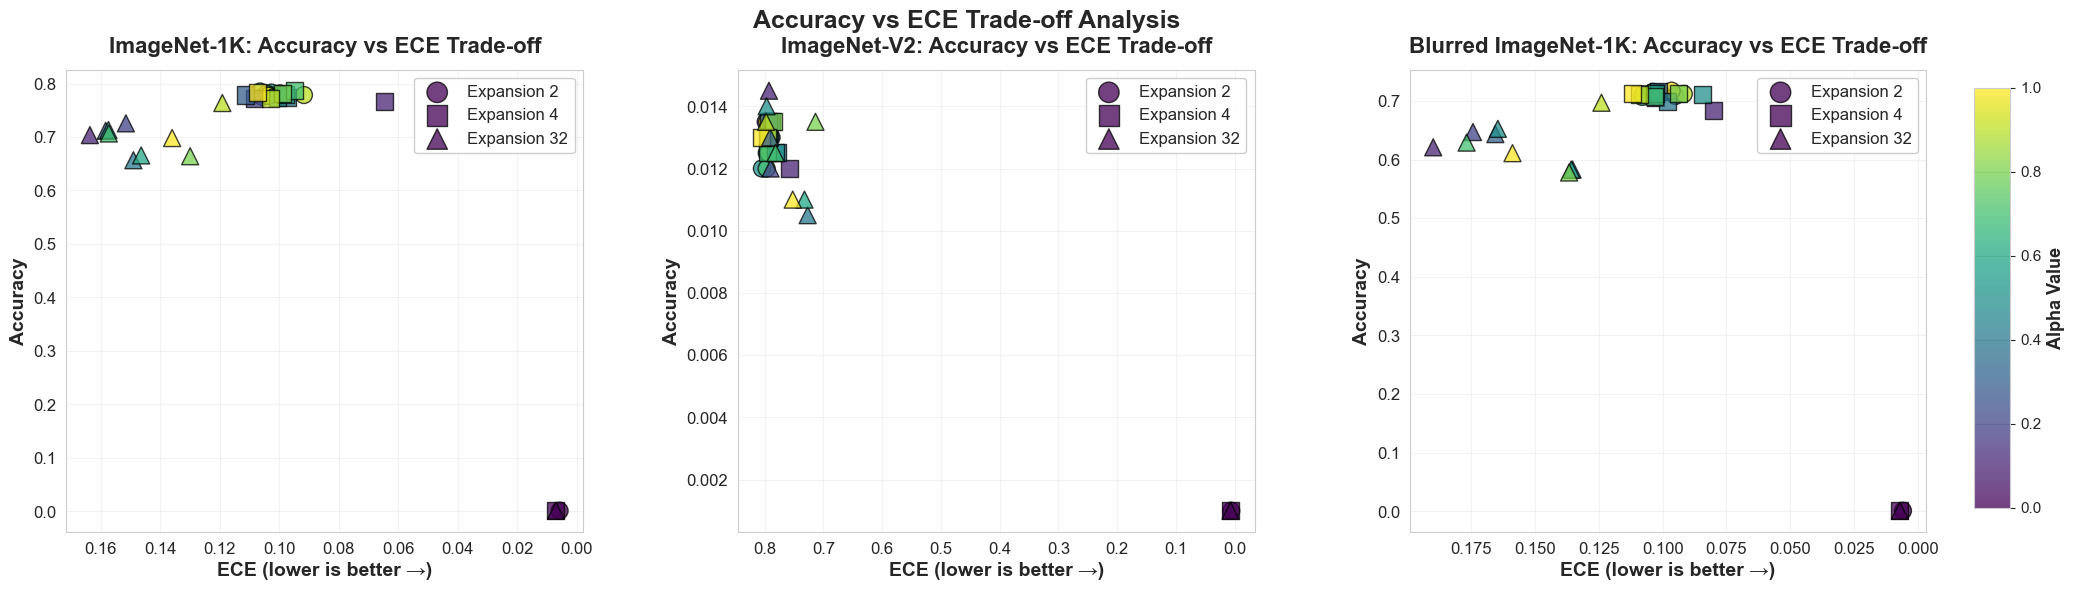

Note: Ideal models are in the top-left corner (high accuracy, low ECE)


In [51]:
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
dataset_pairs = [
    ('imagenet_1k accuracy', 'imagenet_1k ECE', 'ImageNet-1K'),
    ('imagenet_v2 accuracy', 'imagenet_v2 ECE', 'ImageNet-V2'),
    ('blurred_imagenet_1k accuracy', 'blurred_imagenet_1k ECE', 'Blurred ImageNet-1K')
]

for idx, (acc_col, ece_col, title) in enumerate(dataset_pairs):
    ax = axes[idx]
    
    # Plot for each expansion factor with different markers
    markers = ['o', 's', '^']
    for exp, marker in zip(sorted(df_fixed_alpha['expansion'].unique()), markers):
        data = df_fixed_alpha[df_fixed_alpha['expansion'] == exp]
        scatter = ax.scatter(data[ece_col], data[acc_col], 
                           c=data['alpha'], cmap='viridis', 
                           marker=marker, s=150, alpha=0.75, 
                           label=f'Expansion {exp}', edgecolors='black', linewidth=1)
    
    ax.set_xlabel('ECE (lower is better →)', fontsize=14, fontweight='bold')
    ax.set_ylabel('Accuracy', fontsize=14, fontweight='bold')
    ax.set_title(f'{title}: Accuracy vs ECE Trade-off', fontsize=16, fontweight='bold', pad=12)
    ax.legend(loc='best', fontsize=12, framealpha=0.95, markerscale=1.2)
    ax.grid(True, alpha=0.25, linewidth=0.8)
    ax.tick_params(axis='both', labelsize=12)
    ax.invert_xaxis()  # Invert so right = better (lower ECE)

# Add colorbar for alpha values on the right side
fig.subplots_adjust(right=0.90, wspace=0.3)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(scatter, cax=cbar_ax)
cbar.set_label('Alpha Value', fontsize=13, fontweight='bold')
cbar.ax.tick_params(labelsize=11)

plt.suptitle('Accuracy vs ECE Trade-off Analysis', fontsize=18, fontweight='bold', y=0.98)
plt.show()

print("Note: Ideal models are in the top-left corner (high accuracy, low ECE)")


## 8. Heatmaps for Parameter Relationships

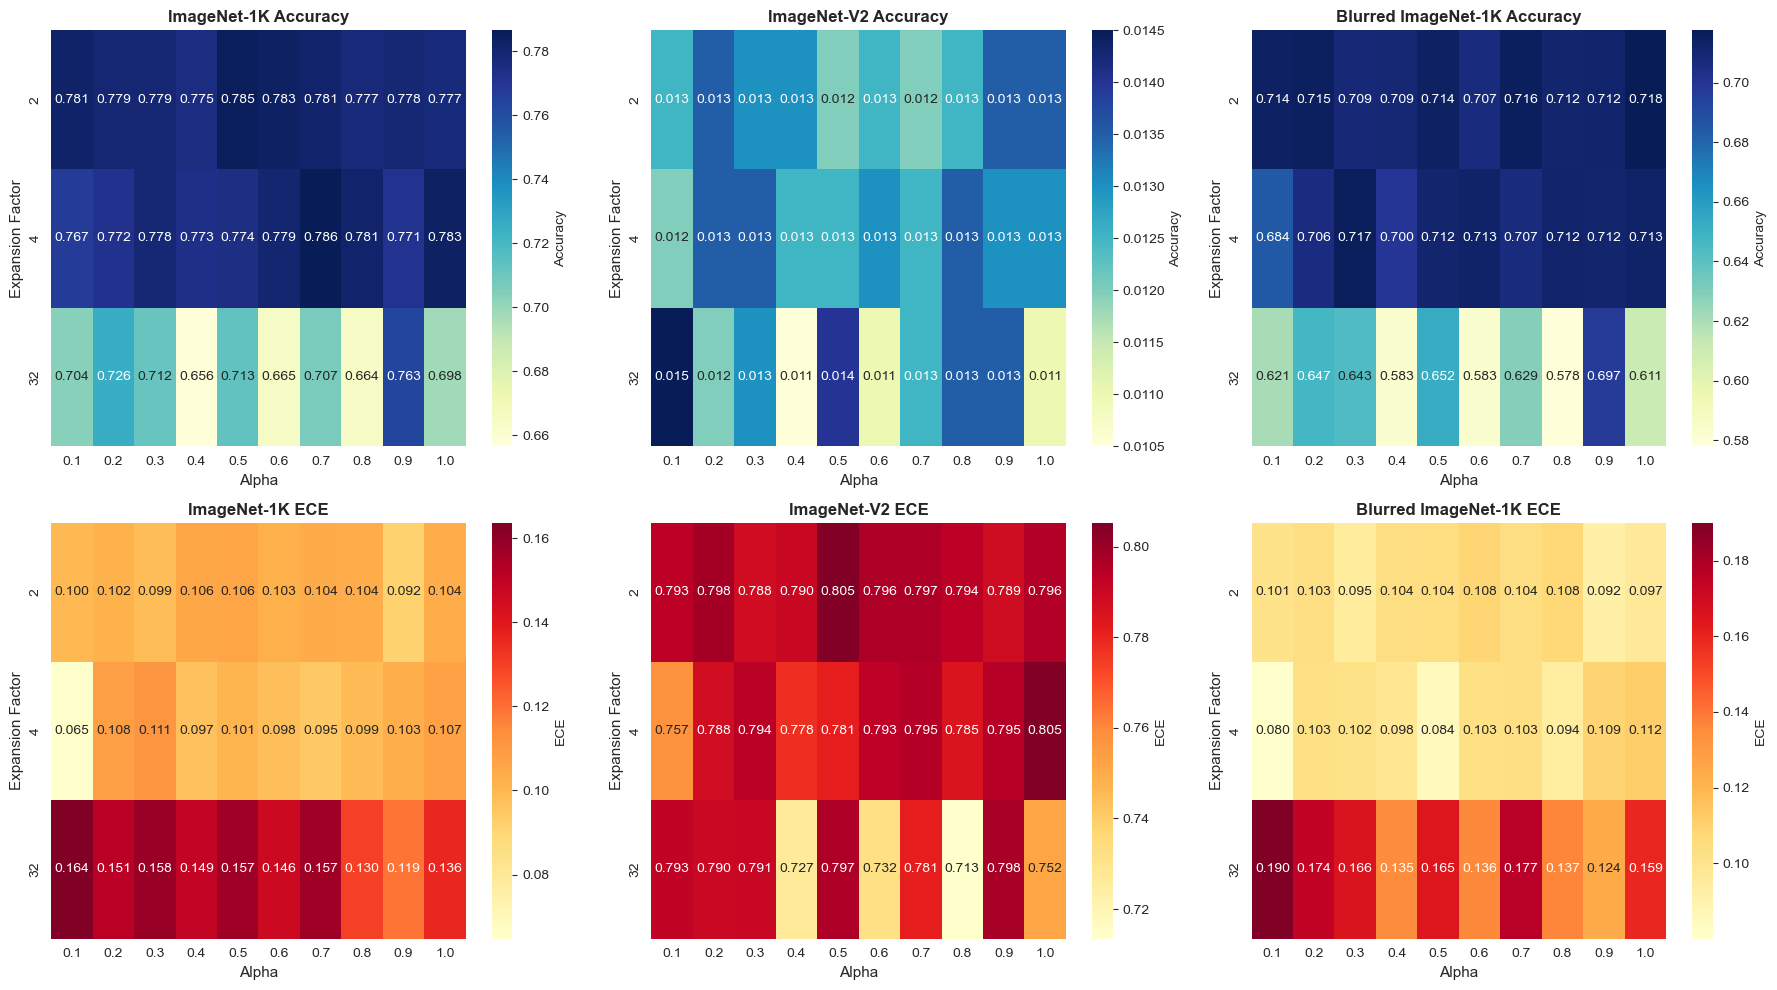

In [11]:
# Create pivot tables for heatmaps (excluding alpha=0 and alpha=-1)
df_heatmap = df_fixed_alpha[(df_fixed_alpha['alpha'] > 0)].copy()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Accuracy heatmaps
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    pivot = df_heatmap.pivot_table(values=dataset, index='expansion', columns='alpha')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Accuracy'})
    ax.set_title(f'{title} Accuracy', fontsize=12, fontweight='bold')
    ax.set_xlabel('Alpha', fontsize=11)
    ax.set_ylabel('Expansion Factor', fontsize=11)

# ECE heatmaps
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    pivot = df_heatmap.pivot_table(values=dataset, index='expansion', columns='alpha')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'ECE'})
    ax.set_title(f'{title} ECE', fontsize=12, fontweight='bold')
    ax.set_xlabel('Alpha', fontsize=11)
    ax.set_ylabel('Expansion Factor', fontsize=11)

plt.tight_layout()
plt.show()

## 9. Performance Relative to Baseline

In [33]:
# Calculate relative performance to baseline (alpha=1.0)
df_relative = df_fixed_alpha[df_fixed_alpha['alpha'] < 1.0].copy()

for exp in sorted(df_relative['expansion'].unique()):
    baseline_row = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    for dataset in datasets:
        col_name = f'{dataset}_rel'
        df_relative.loc[df_relative['expansion'] == exp, col_name] = \
            ((df_relative.loc[df_relative['expansion'] == exp, dataset] - baseline_row[dataset]) / baseline_row[dataset]) * 100
    
    for dataset in ece_datasets:
        col_name = f'{dataset}_rel'
        df_relative.loc[df_relative['expansion'] == exp, col_name] = \
            ((df_relative.loc[df_relative['expansion'] == exp, dataset] - baseline_row[dataset]) / baseline_row[dataset]) * 100

print("Calculated relative performance to baseline (alpha=1.0)")

Calculated relative performance to baseline (alpha=1.0)


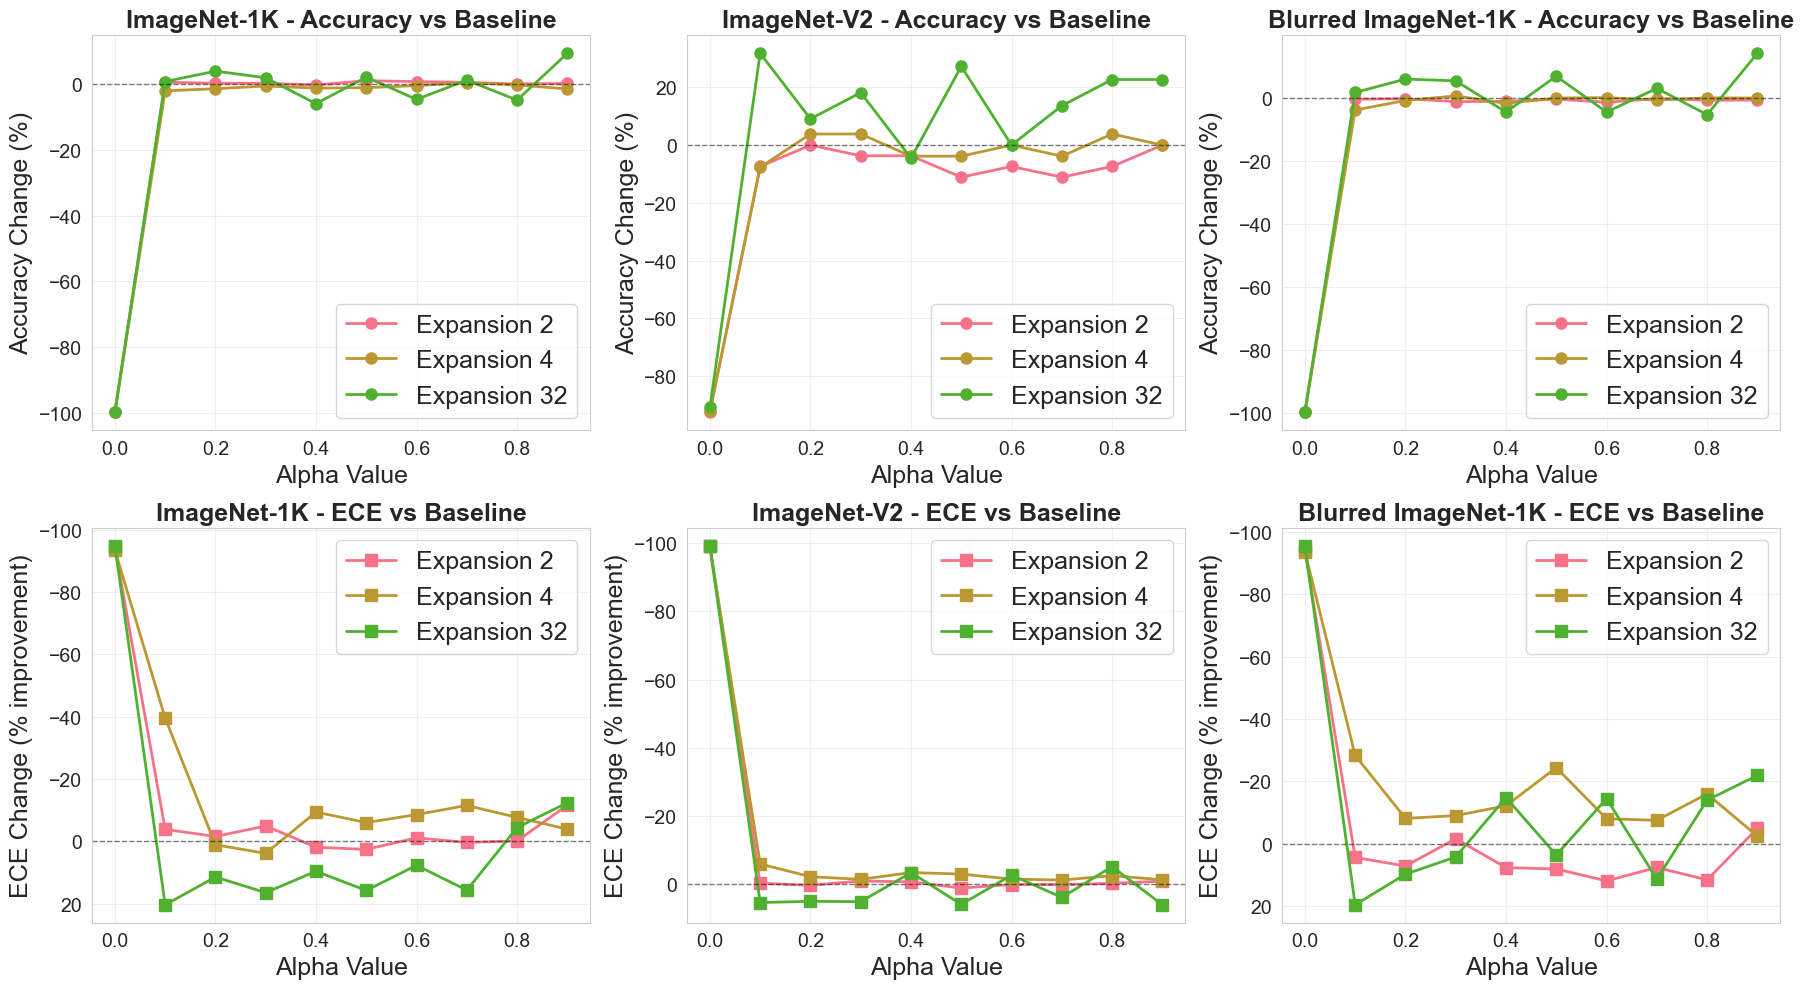

Positive values indicate improvement over baseline for accuracy
Negative values indicate improvement over baseline for ECE (lower is better)


In [73]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Font size settings
label_fontsize = 18  # slightly bigger
title_fontsize = 18  # reduced to avoid overlap
legend_fontsize = 18
tick_fontsize = 14

# Relative accuracy plots
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    col_name = f'{dataset}_rel'
    
    for exp in sorted(df_relative['expansion'].unique()):
        data = df_relative[df_relative['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='o', linewidth=2, 
                label=f'Expansion {exp}', markersize=8)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=label_fontsize)
    ax.set_ylabel('Accuracy Change (%)', fontsize=label_fontsize)
    ax.set_title(f'{title} - Accuracy vs Baseline', fontsize=title_fontsize, fontweight='bold')
    ax.legend(loc='best', fontsize=legend_fontsize)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', labelsize=tick_fontsize)

# Relative ECE plots
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    col_name = f'{dataset}_rel'
    
    for exp in sorted(df_relative['expansion'].unique()):
        data = df_relative[df_relative['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='s', linewidth=2, 
                label=f'Expansion {exp}', markersize=8)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=label_fontsize)
    ax.set_ylabel('ECE Change (% improvement)', fontsize=label_fontsize)
    ax.set_title(f'{title} - ECE vs Baseline', fontsize=title_fontsize, fontweight='bold')
    ax.legend(loc='best', fontsize=legend_fontsize)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.invert_yaxis()  # Invert so upward = better (lower ECE)

plt.tight_layout()
plt.show()

print("Positive values indicate improvement over baseline for accuracy")
print("Negative values indicate improvement over baseline for ECE (lower is better)")

## Performance Relative to Scheduled Alpha (alpha=-1)

## 10. Summary Statistics and Best Configurations

In [78]:
# Find best configurations for each metric, separated by expansion factor
print("=" * 80)
print("BEST CONFIGURATIONS BY METRIC (SEPARATED BY EXPANSION FACTOR)")
print("=" * 80)

# Include all models (fixed alpha and scheduled)
df_all_models = df[df['alpha'] != 0].copy()  # Exclude only alpha=0

for exp in sorted(df_all_models['expansion'].unique()):
    print(f"\n{'=' * 80}")
    print(f"EXPANSION FACTOR {exp}")
    print('=' * 80)
    
    df_exp = df_all_models[df_all_models['expansion'] == exp].copy()
    baseline_exp = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    for dataset, title in zip(datasets, titles):
        print(f"\n{title} - Top 2 Highest Accuracy:")
        top_indices = df_exp.nlargest(2, dataset).index
        for rank, idx in enumerate(top_indices, 1):
            best_row = df_exp.loc[idx]
            alpha_label = "Scheduled" if best_row['alpha'] == -1 else f"{best_row['alpha']:.1f}"
            print(f"  #{rank}: Alpha: {alpha_label}, Accuracy: {best_row[dataset]:.4f}")
        
        # Show baseline performance for reference
        print(f"  Reference - Baseline (alpha=1.0): {baseline_exp[dataset]:.4f}")
    
    print("\n" + "-" * 80)
    
    for dataset, title in zip(ece_datasets, titles):
        print(f"\n{title} - Top 2 Lowest ECE:")
        top_indices = df_exp.nsmallest(2, dataset).index
        for rank, idx in enumerate(top_indices, 1):
            best_row = df_exp.loc[idx]
            alpha_label = "Scheduled" if best_row['alpha'] == -1 else f"{best_row['alpha']:.1f}"
            print(f"  #{rank}: Alpha: {alpha_label}, ECE: {best_row[dataset]:.4f}")
        
        # Show baseline performance for reference
        print(f"  Reference - Baseline (alpha=1.0): {baseline_exp[dataset]:.4f}")

print("\n" + "=" * 80)

BEST CONFIGURATIONS BY METRIC (SEPARATED BY EXPANSION FACTOR)

EXPANSION FACTOR 2

ImageNet-1K - Top 2 Highest Accuracy:
  #1: Alpha: 0.5, Accuracy: 0.7850
  #2: Alpha: 0.6, Accuracy: 0.7830
  Reference - Baseline (alpha=1.0): 0.7770

ImageNet-V2 - Top 2 Highest Accuracy:
  #1: Alpha: 0.2, Accuracy: 0.0135
  #2: Alpha: 0.9, Accuracy: 0.0135
  Reference - Baseline (alpha=1.0): 0.0135

Blurred ImageNet-1K - Top 2 Highest Accuracy:
  #1: Alpha: 1.0, Accuracy: 0.7175
  #2: Alpha: 0.7, Accuracy: 0.7155
  Reference - Baseline (alpha=1.0): 0.7175

--------------------------------------------------------------------------------

ImageNet-1K - Top 2 Lowest ECE:
  #1: Alpha: Scheduled, ECE: 0.0654
  #2: Alpha: 0.9, ECE: 0.0917
  Reference - Baseline (alpha=1.0): 0.1038

ImageNet-V2 - Top 2 Lowest ECE:
  #1: Alpha: Scheduled, ECE: 0.7427
  #2: Alpha: 0.3, ECE: 0.7882
  Reference - Baseline (alpha=1.0): 0.7956

Blurred ImageNet-1K - Top 2 Lowest ECE:
  #1: Alpha: Scheduled, ECE: 0.0841
  #2: Alpha

## Models That Outperform Baseline Across All Metrics

In [79]:
# Compare scheduled vs fixed alpha performance
print("\n" + "=" * 80)
print("SCHEDULED ALPHA (-1) vs BASELINE (1.0) COMPARISON")
print("=" * 80)

for exp in sorted(df['expansion'].unique()):
    print(f"\nExpansion Factor {exp}:")
    scheduled = df_scheduled[df_scheduled['expansion'] == exp].iloc[0]
    baseline = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    for dataset, title in zip(datasets, titles):
        acc_diff = (scheduled[dataset] - baseline[dataset]) * 100
        print(f"  {title} Accuracy: Scheduled={scheduled[dataset]:.4f}, Baseline={baseline[dataset]:.4f}, Diff={acc_diff:+.2f}%")
    
    for dataset, title in zip(ece_datasets, titles):
        ece_diff = (scheduled[dataset] - baseline[dataset]) / baseline[dataset] * 100
        print(f"  {title} ECE: Scheduled={scheduled[dataset]:.4f}, Baseline={baseline[dataset]:.4f}, Diff={ece_diff:+.2f}%")

print("\n" + "=" * 80)


SCHEDULED ALPHA (-1) vs BASELINE (1.0) COMPARISON

Expansion Factor 2:
  ImageNet-1K Accuracy: Scheduled=0.7540, Baseline=0.7770, Diff=-2.30%
  ImageNet-V2 Accuracy: Scheduled=0.0120, Baseline=0.0135, Diff=-0.15%
  Blurred ImageNet-1K Accuracy: Scheduled=0.6855, Baseline=0.7175, Diff=-3.20%
  ImageNet-1K ECE: Scheduled=0.0654, Baseline=0.1038, Diff=-37.00%
  ImageNet-V2 ECE: Scheduled=0.7427, Baseline=0.7956, Diff=-6.65%
  Blurred ImageNet-1K ECE: Scheduled=0.0841, Baseline=0.0965, Diff=-12.85%

Expansion Factor 4:
  ImageNet-1K Accuracy: Scheduled=0.7590, Baseline=0.7830, Diff=-2.40%
  ImageNet-V2 Accuracy: Scheduled=0.0125, Baseline=0.0130, Diff=-0.05%
  Blurred ImageNet-1K Accuracy: Scheduled=0.6995, Baseline=0.7125, Diff=-1.30%
  ImageNet-1K ECE: Scheduled=0.0754, Baseline=0.1072, Diff=-29.61%
  ImageNet-V2 ECE: Scheduled=0.7576, Baseline=0.8052, Diff=-5.92%
  Blurred ImageNet-1K ECE: Scheduled=0.0821, Baseline=0.1117, Diff=-26.52%

Expansion Factor 32:
  ImageNet-1K Accuracy: Sch

In [18]:
# Calculate relative performance to scheduled alpha (alpha=-1)
df_relative_scheduled = df_fixed_alpha[df_fixed_alpha['alpha'] >= 0].copy()

for exp in sorted(df_relative_scheduled['expansion'].unique()):
    scheduled_row = df_scheduled[df_scheduled['expansion'] == exp].iloc[0]
    
    for dataset in datasets:
        col_name = f'{dataset}_rel_sched'
        df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, col_name] = \
            ((df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, dataset] - scheduled_row[dataset]) / scheduled_row[dataset]) * 100
    
    for dataset in ece_datasets:
        col_name = f'{dataset}_rel_sched'
        df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, col_name] = \
            ((df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, dataset] - scheduled_row[dataset]) / scheduled_row[dataset]) * 100

print("Calculated relative performance to scheduled alpha (alpha=-1)")

Calculated relative performance to scheduled alpha (alpha=-1)


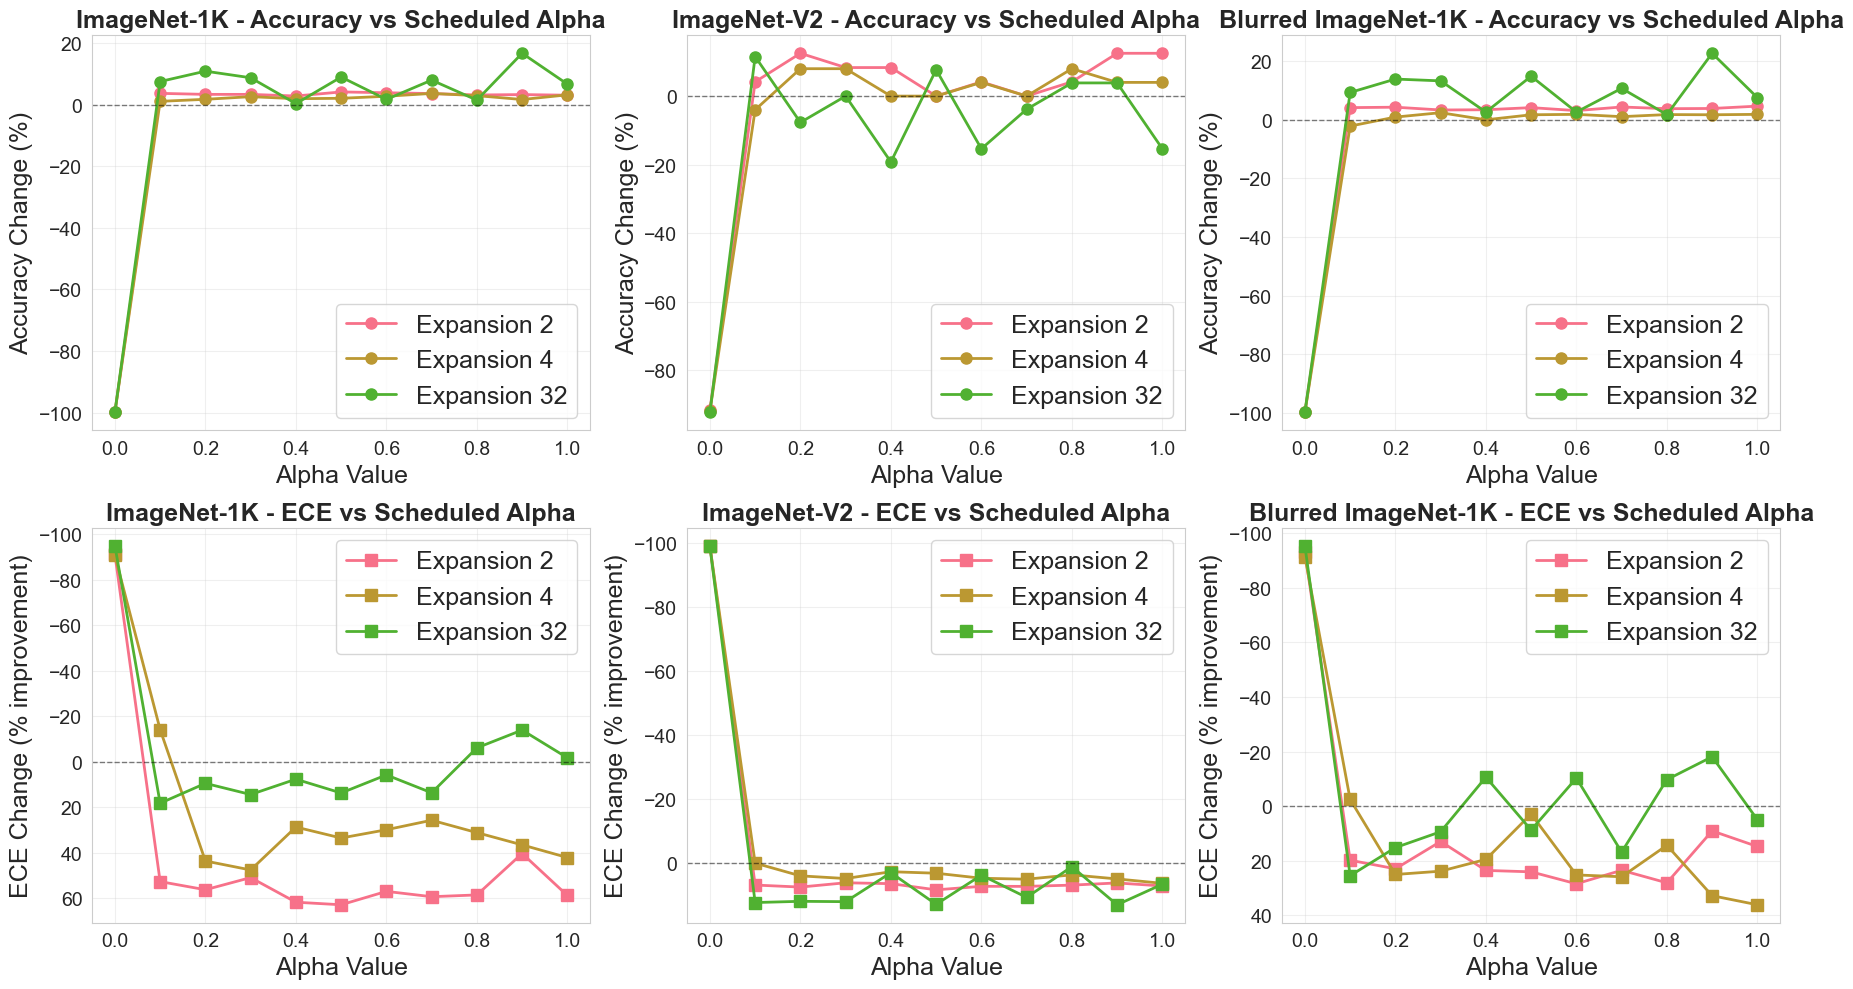

Positive values indicate improvement over scheduled alpha for accuracy
Negative values indicate improvement over scheduled alpha for ECE (lower is better)


In [74]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Font size settings
label_fontsize = 18  # slightly bigger
title_fontsize = 18  # reduced to avoid overlap
legend_fontsize = 18
tick_fontsize = 14

# Relative accuracy plots
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    col_name = f'{dataset}_rel_sched'
    
    for exp in sorted(df_relative_scheduled['expansion'].unique()):
        data = df_relative_scheduled[df_relative_scheduled['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='o', linewidth=2, 
                label=f'Expansion {exp}', markersize=8)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=label_fontsize)
    ax.set_ylabel('Accuracy Change (%)', fontsize=label_fontsize)
    ax.set_title(f'{title} - Accuracy vs Scheduled Alpha', fontsize=title_fontsize, fontweight='bold')
    ax.legend(loc='best', fontsize=legend_fontsize)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', labelsize=tick_fontsize)

# Relative ECE plots
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    col_name = f'{dataset}_rel_sched'
    
    for exp in sorted(df_relative_scheduled['expansion'].unique()):
        data = df_relative_scheduled[df_relative_scheduled['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='s', linewidth=2, 
                label=f'Expansion {exp}', markersize=8)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=label_fontsize)
    ax.set_ylabel('ECE Change (% improvement)', fontsize=label_fontsize)
    ax.set_title(f'{title} - ECE vs Scheduled Alpha', fontsize=title_fontsize, fontweight='bold')
    ax.legend(loc='best', fontsize=legend_fontsize)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.invert_yaxis()  # Invert so upward = better (lower ECE)

plt.tight_layout()
plt.show()

print("Positive values indicate improvement over scheduled alpha for accuracy")
print("Negative values indicate improvement over scheduled alpha for ECE (lower is better)")

In [24]:
# Find models that beat baseline in ALL accuracy OR ALL ECE metrics
from IPython.display import display, HTML
print('=' * 80)
print('MODELS THAT OUTPERFORM BASELINE (ALPHA=1.0)')
print('In All Accuracy Metrics OR All ECE Metrics')
print('=' * 80)

# For each expansion factor, find models that beat baseline
all_winners = []
rows = []

for exp in sorted(df_all_models['expansion'].unique()):
    df_exp = df_all_models[df_all_models['expansion'] == exp].copy()
    baseline_exp = df_baseline[df_baseline['expansion'] == exp].iloc[0]

    for idx, row in df_exp.iterrows():
        if row['alpha'] == 1.0:  # Skip baseline itself
            continue

        beats_all_accuracy = all(row[dataset] > baseline_exp[dataset] for dataset in datasets)
        beats_all_ece = all(row[dataset] < baseline_exp[dataset] for dataset in ece_datasets)

        if beats_all_accuracy or beats_all_ece:
            alpha_label = 'Scheduled' if row['alpha'] == -1 else f"{row['alpha']:.1f}"
            rows.append({
                'expansion': exp,
                'alpha': row['alpha'],
                'alpha_label': alpha_label,
                'beats_accuracy': beats_all_accuracy,
                'beats_ece': beats_all_ece,
            })
            all_winners.append({
                'expansion': exp,
                'alpha': row['alpha'],
                'alpha_label': alpha_label,
                'beats_accuracy': beats_all_accuracy,
                'beats_ece': beats_all_ece
            })

# Present results as a DataFrame
import pandas as _pd
if len(rows) == 0:
    print('
else:
    winners_df = _pd.DataFrame(rows)
    display(HTML(f'<h3>Found {len(winners_df)} model(s) that beat baseline</h3>'))
    display(winners_df.sort_values(['expansion', 'alpha']).reset_index(drop=True))

# Overall summary counts
beats_both = sum(1 for w in rows if w['beats_accuracy'] and w['beats_ece'])
beats_accuracy_only = sum(1 for w in rows if w['beats_accuracy'] and not w['beats_ece'])
beats_ece_only = sum(1 for w in rows if w['beats_ece'] and not w['beats_accuracy'])

print()
print('SUMMARY')
print(f'  - Beat baseline in ALL accuracy AND ALL ECE metrics: {beats_both}')
print(f'  - Beat baseline in ALL accuracy metrics only: {beats_accuracy_only}')
print(f'  - Beat baseline in ALL ECE metrics only: {beats_ece_only}')

if all_winners:
    print('
    for exp in sorted(df_all_models['expansion'].unique()):
        exp_winners = [w for w in all_winners if w['expansion'] == exp]
        count = len(exp_winners)
        print(f'  Expansion {exp}: {count} model(s)')
        models = [w['alpha_label'] for w in exp_winners]
        if models:
            print(f'    Alpha values: {', '.join(models)}')

# keep all_winners for downstream visualization cells
print('
            print(f"    Alpha values: {', '.join(models)}")

print("\n" + "=" * 80)

MODELS THAT OUTPERFORM BASELINE (ALPHA=1.0)
In All Accuracy Metrics OR All ECE Metrics

EXPANSION FACTOR 2

Found 3 model(s) that beat baseline:

Model #1: Alpha = Scheduled (Beats: All ECE Metrics)
----------------------------------------
  ✗ ImageNet-1K Accuracy: 0.7540 (Baseline: 0.7770, Change: -2.96%)
  ✗ ImageNet-V2 Accuracy: 0.0120 (Baseline: 0.0135, Change: -11.11%)
  ✗ Blurred ImageNet-1K Accuracy: 0.6855 (Baseline: 0.7175, Change: -4.46%)
  ✓ ImageNet-1K ECE: 0.0654 (Baseline: 0.1038, Change: -37.00%)
  ✓ ImageNet-V2 ECE: 0.7427 (Baseline: 0.7956, Change: -6.65%)
  ✓ Blurred ImageNet-1K ECE: 0.0841 (Baseline: 0.0965, Change: -12.85%)

Model #2: Alpha = 0.3 (Beats: All ECE Metrics)
----------------------------------------
  ✓ ImageNet-1K Accuracy: 0.7790 (Baseline: 0.7770, Change: +0.26%)
  ✗ ImageNet-V2 Accuracy: 0.0130 (Baseline: 0.0135, Change: -3.70%)
  ✗ Blurred ImageNet-1K Accuracy: 0.7085 (Baseline: 0.7175, Change: -1.25%)
  ✓ ImageNet-1K ECE: 0.0986 (Baseline: 0.1038, 

Expansion factor 2: Alpha values: Scheduled, 0.3, 0.9
Expansion factor 4: Alpha values: Scheduled, 0.1, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9
Expansion factor 32: Alpha values: 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9


/var/folders/l8/tp2sn6_j48ddt15xflhpdr5r0000gn/T/ipykernel_83459/3276603110.py:56: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(categories, fontsize=14, fontweight='bold')


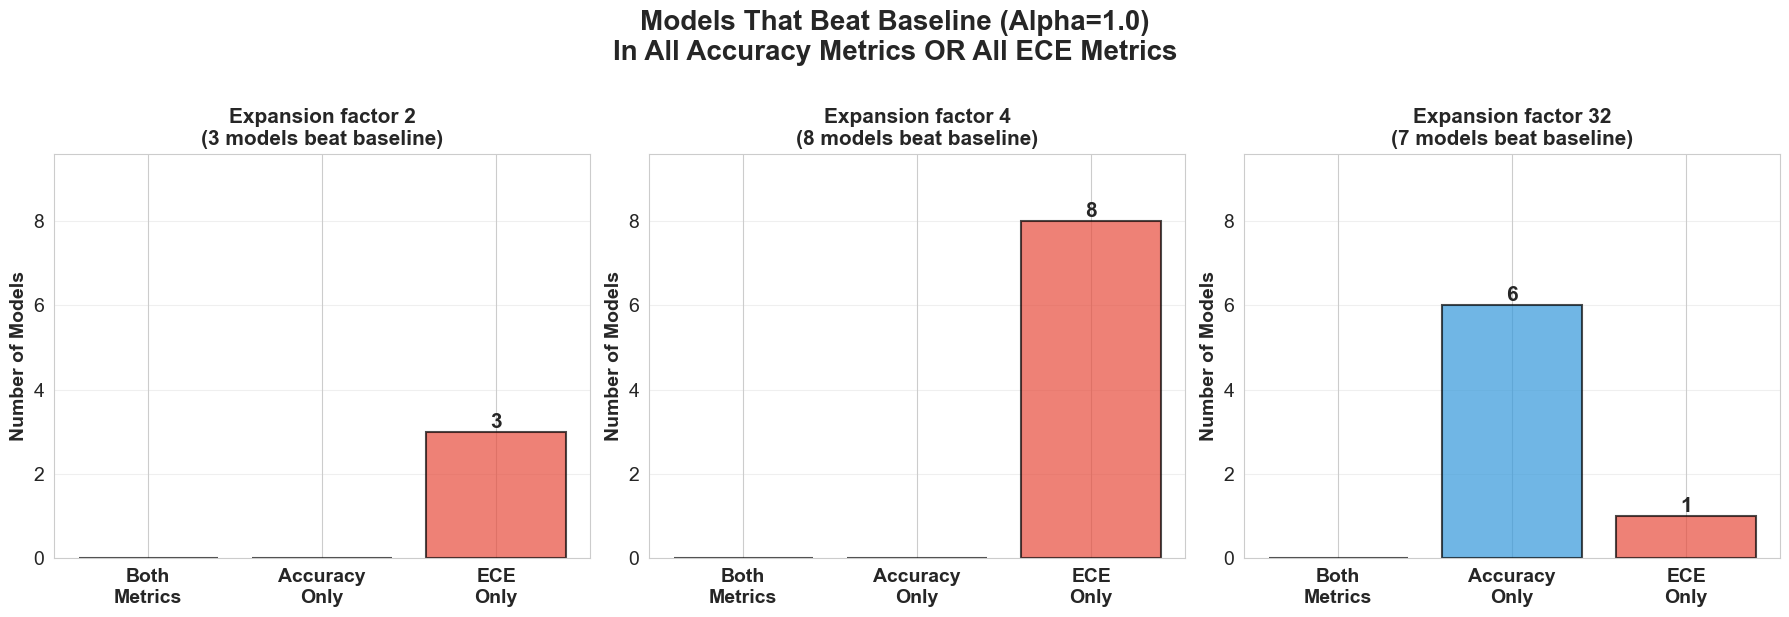

In [93]:
# Visualize models that beat baseline in all accuracy OR all ECE metrics
if all_winners:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Determine global y-axis limits
    global_max = 0
    for exp in sorted(df_all_models['expansion'].unique()):
        exp_winners = [w for w in all_winners if w['expansion'] == exp]
        if exp_winners:
            beats_both_count = sum(1 for w in exp_winners if w['beats_accuracy'] and w['beats_ece'])
            beats_acc_only = sum(1 for w in exp_winners if w['beats_accuracy'] and not w['beats_ece'])
            beats_ece_only = sum(1 for w in exp_winners if w['beats_ece'] and not w['beats_accuracy'])
            global_max = max(global_max, beats_both_count, beats_acc_only, beats_ece_only)

    for idx, exp in enumerate(sorted(df_all_models['expansion'].unique())):
        ax = axes[idx]

        # Get winners for this expansion factor
        exp_winners = [w for w in all_winners if w['expansion'] == exp]

        if exp_winners:
            # Prepare data for visualization
            winner_alphas = [w['alpha'] for w in exp_winners]
            winner_labels = [w['alpha_label'] for w in exp_winners]

            # Print alpha values in the terminal
            print(f"Expansion factor {exp}: Alpha values: {', '.join(winner_labels)}")

            # Count how many criteria each model beats
            beats_both_count = sum(1 for w in exp_winners if w['beats_accuracy'] and w['beats_ece'])
            beats_acc_only = sum(1 for w in exp_winners if w['beats_accuracy'] and not w['beats_ece'])
            beats_ece_only = sum(1 for w in exp_winners if w['beats_ece'] and not w['beats_accuracy'])

            # Create stacked bar chart
            categories = ['Both\nMetrics', 'Accuracy\nOnly', 'ECE\nOnly']
            counts = [beats_both_count, beats_acc_only, beats_ece_only]
            colors = ['#2ecc71', '#3498db', '#e74c3c']

            bars = ax.bar(categories, counts, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)

            # Add count labels on bars
            for bar, count in zip(bars, counts):
                if count > 0:
                    height = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2., height,
                           f'{int(count)}',
                           ha='center', va='bottom', fontweight='bold', fontsize=15)

            ax.set_ylabel('Number of Models', fontsize=14, fontweight='bold')
            ax.set_title(f'Expansion factor {exp}\n({len(exp_winners)} models beat baseline)', 
                        fontsize=15, fontweight='bold')
            ax.set_ylim(0, global_max * 1.2 if global_max > 0 else 1)
            ax.grid(True, alpha=0.3, axis='y')

            # Set larger font size for x-axis labels and y-axis ticks
            ax.set_xticklabels(categories, fontsize=14, fontweight='bold')
            ax.tick_params(axis='y', labelsize=14)
        else:
            ax.text(0.5, 0.5, 'No models\nbeat baseline',
                   transform=ax.transAxes, ha='center', va='center',
                   fontsize=20, fontweight='bold', color='gray')
            ax.set_title(f'Expansion {exp}', fontsize=15, fontweight='bold')
            ax.set_ylabel('Number of Models', fontsize=14, fontweight='bold')
            ax.set_xticks([], fontsize=20)

    plt.suptitle('Models That Beat Baseline (Alpha=1.0)\nIn All Accuracy Metrics OR All ECE Metrics',
                fontsize=20, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No models found that beat baseline - skipping visualization.")

/var/folders/l8/tp2sn6_j48ddt15xflhpdr5r0000gn/T/ipykernel_83459/2019406172.py:106: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 0.96])


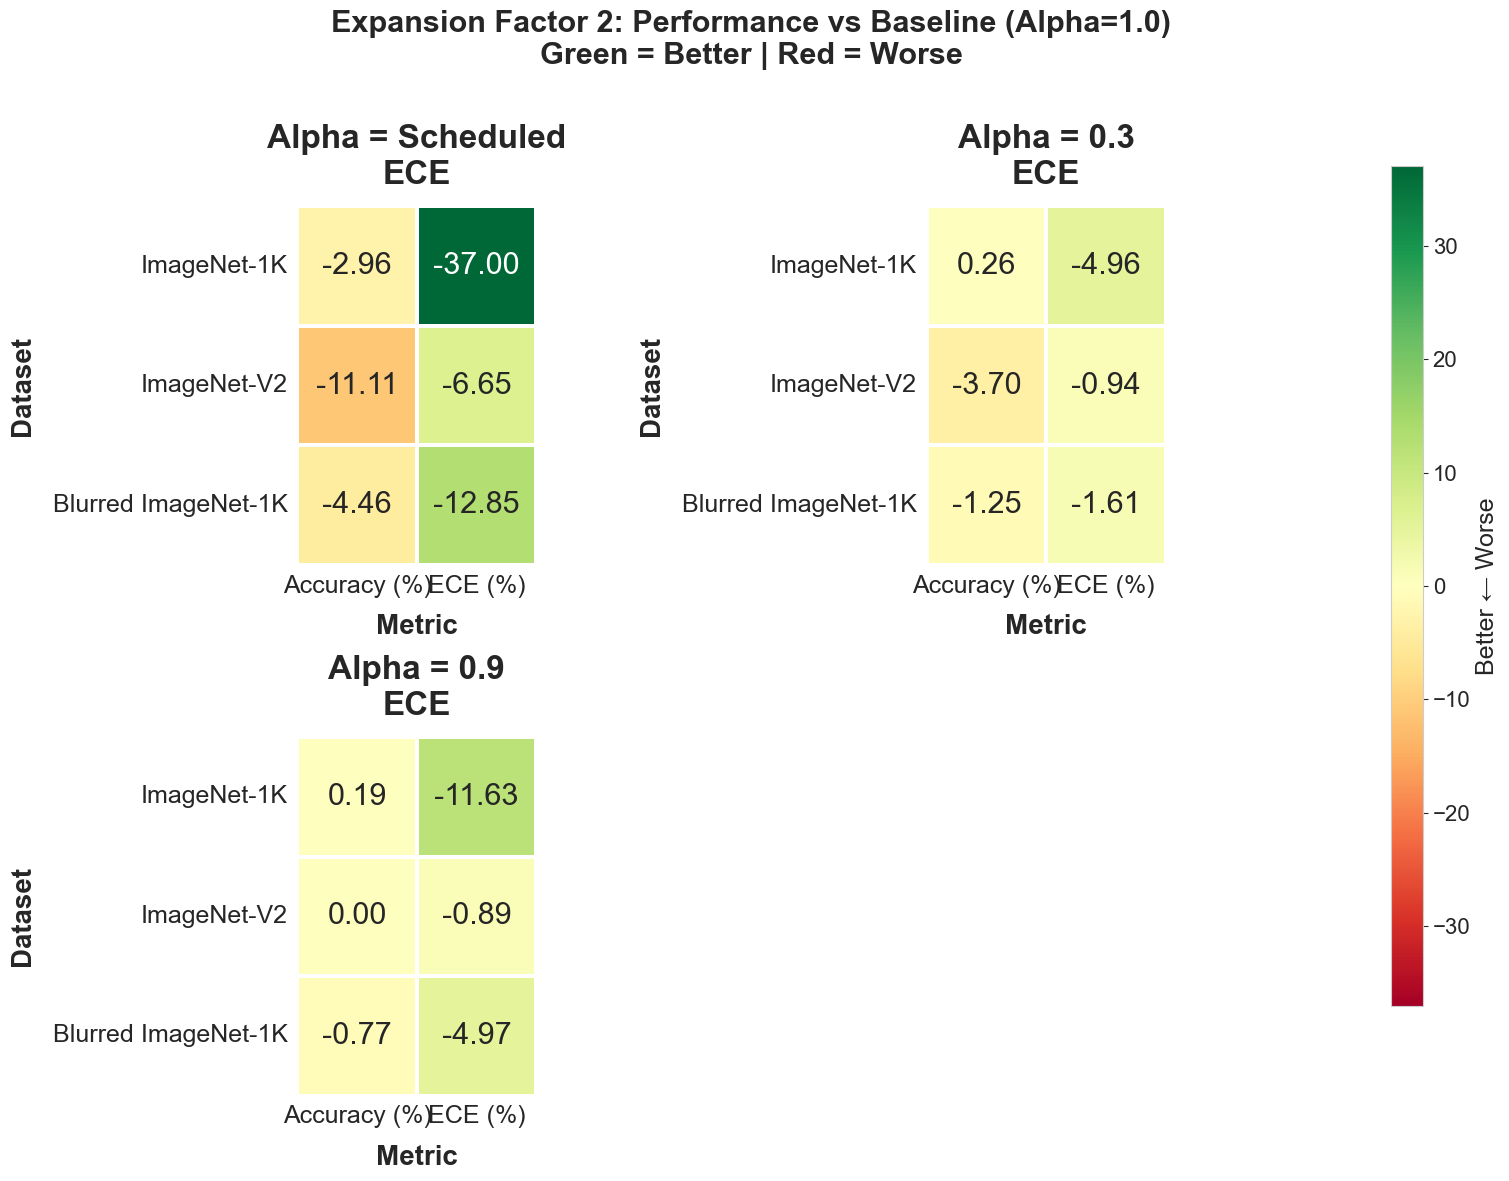

Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).



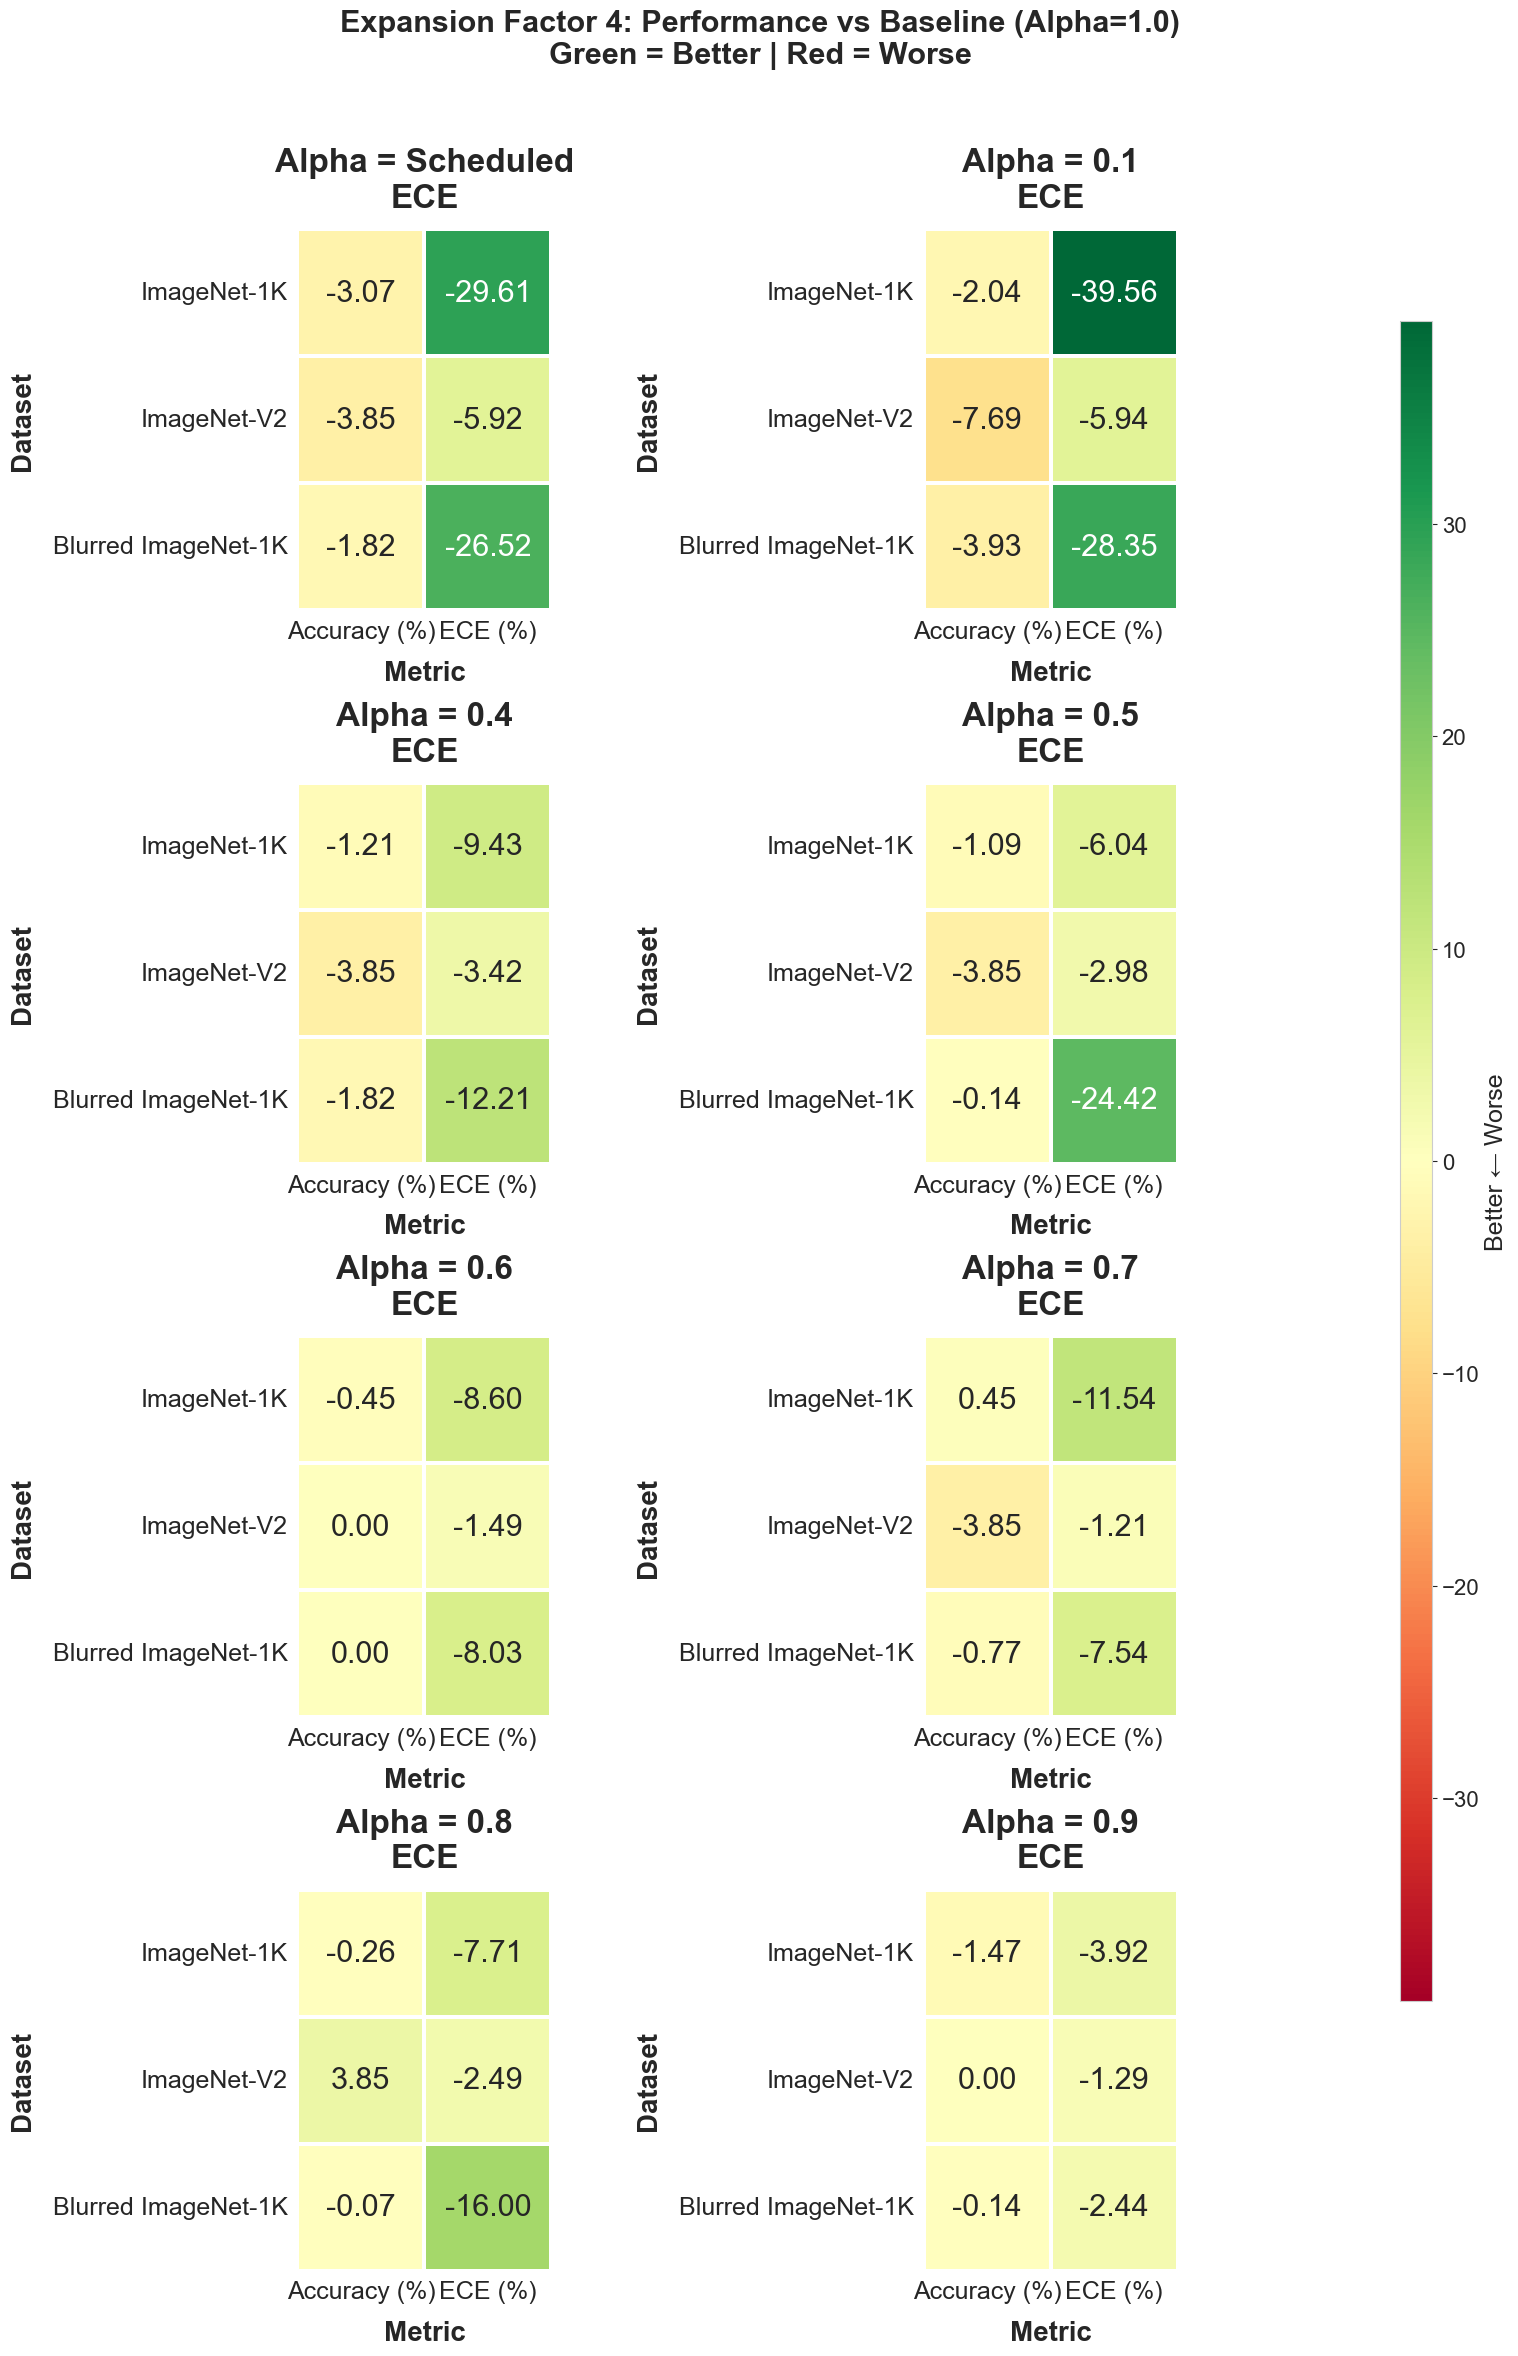

Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).



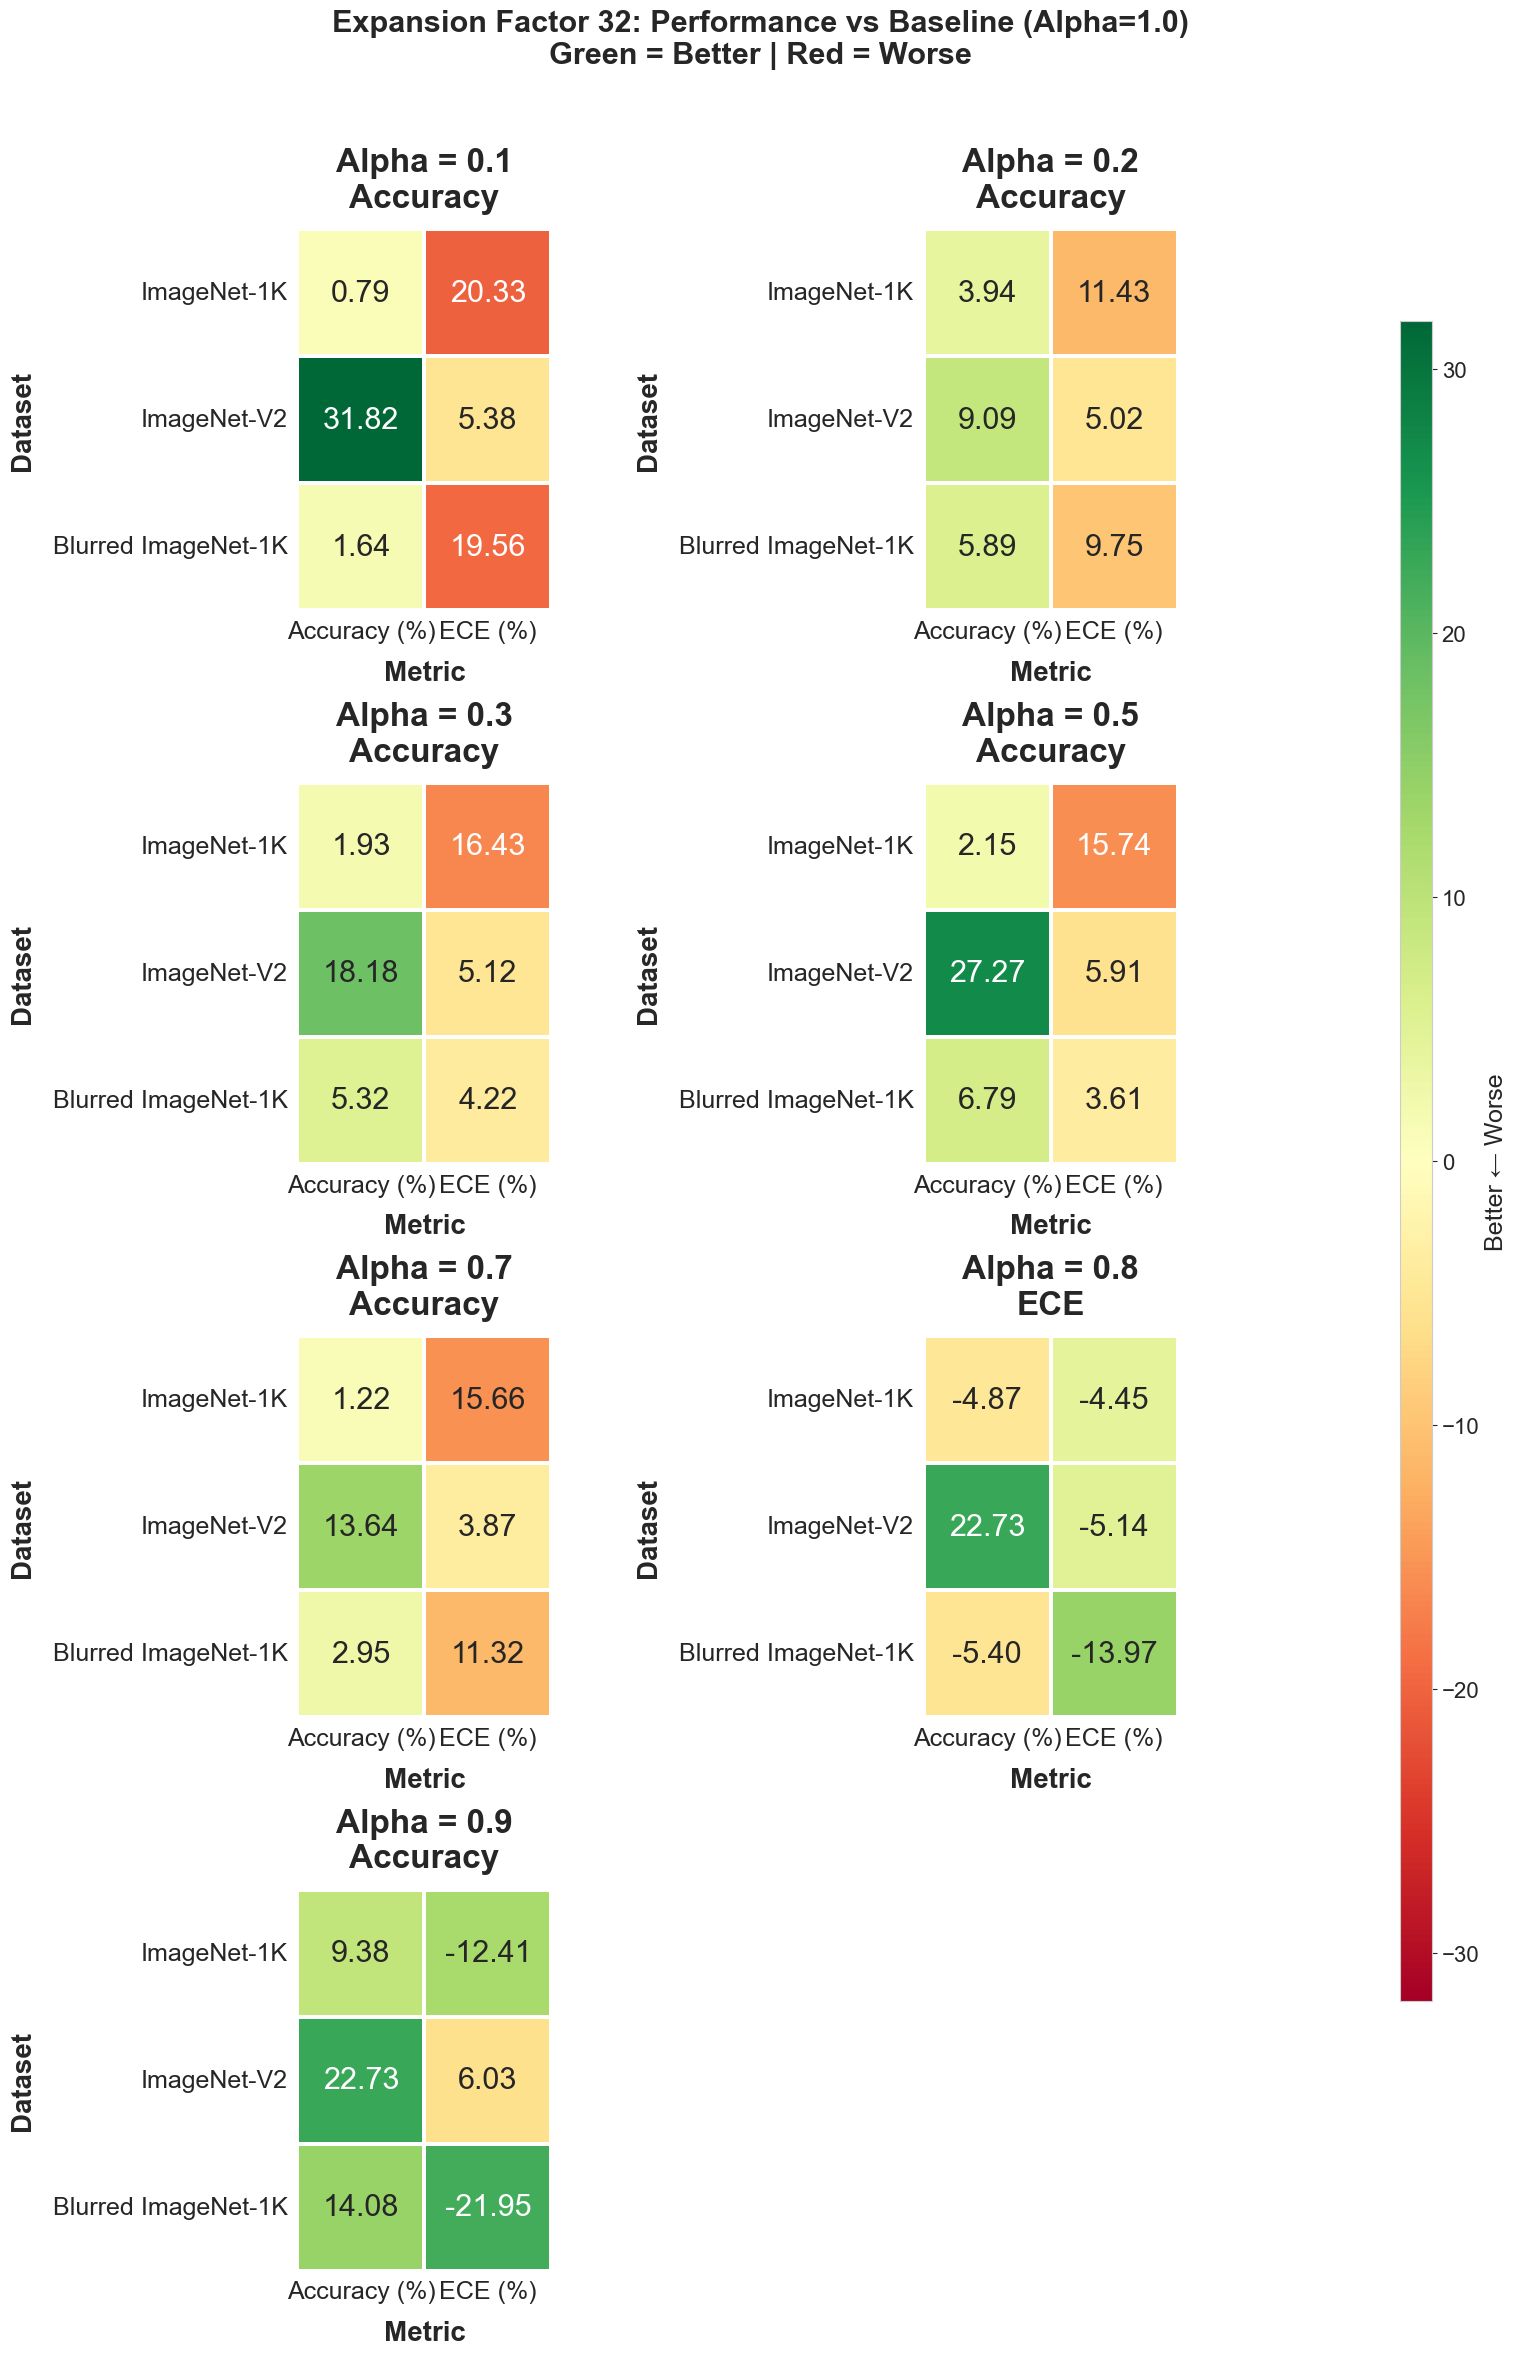

Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).



In [57]:
# Create detailed heatmaps for each winning model showing % change from baseline
if all_winners:
    for exp in sorted(df_all_models['expansion'].unique()):
        exp_winners = [w for w in all_winners if w['expansion'] == exp]
        
        if exp_winners:
            # Calculate number of rows needed (2 models per row)
            n_models = len(exp_winners)
            n_cols = 2
            n_rows = (n_models + 1) // 2
            
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 6*n_rows))
            
            # Ensure axes is always 2D for consistent indexing
            if n_rows == 1:
                axes = axes.reshape(1, -1)
            
            baseline_exp = df_baseline[df_baseline['expansion'] == exp].iloc[0]
            df_exp = df_all_models[df_all_models['expansion'] == exp].copy()
            
            # Calculate global vmin/vmax across all heatmaps for consistent coloring
            global_vmax = 0
            for winner_dict in exp_winners:
                alpha_val = winner_dict['alpha']
                winner = df_exp[df_exp['alpha'] == alpha_val].iloc[0]
                
                percent_matrix = []
                for dataset_acc, dataset_ece in zip(datasets, ece_datasets):
                    acc_change = ((winner[dataset_acc] - baseline_exp[dataset_acc]) / baseline_exp[dataset_acc]) * 100
                    ece_change = ((winner[dataset_ece] - baseline_exp[dataset_ece]) / baseline_exp[dataset_ece]) * 100
                    percent_matrix.append([acc_change, ece_change])
                
                data_matrix = np.array(percent_matrix)
                adjusted_matrix = data_matrix.copy()
                adjusted_matrix[:, 1] = -adjusted_matrix[:, 1]
                
                vmax = max(abs(adjusted_matrix.min()), abs(adjusted_matrix.max()))
                global_vmax = max(global_vmax, vmax)
            
            global_vmin = -global_vmax
            
            # Track the last heatmap for creating shared colorbar
            last_heatmap = None
            
            for idx, winner_dict in enumerate(exp_winners):
                row = idx // 2
                col = idx % 2
                ax = axes[row, col]
                
                # Get the winner data from the dataframe
                alpha_val = winner_dict['alpha']
                alpha_label = winner_dict['alpha_label']
                winner = df_exp[df_exp['alpha'] == alpha_val].iloc[0]
                
                # Create matrix of percentage changes
                percent_matrix = []
                for dataset_acc, dataset_ece in zip(datasets, ece_datasets):
                    acc_change = ((winner[dataset_acc] - baseline_exp[dataset_acc]) / baseline_exp[dataset_acc]) * 100
                    ece_change = ((winner[dataset_ece] - baseline_exp[dataset_ece]) / baseline_exp[dataset_ece]) * 100
                    percent_matrix.append([acc_change, ece_change])
                
                data_matrix = np.array(percent_matrix)
                adjusted_matrix = data_matrix.copy()
                adjusted_matrix[:, 1] = -adjusted_matrix[:, 1]
                
                # Create heatmap without individual colorbar - using red-green colormap
                last_heatmap = sns.heatmap(adjusted_matrix, annot=data_matrix, fmt='.2f', 
                           cmap='RdYlGn', center=0, vmin=global_vmin, vmax=global_vmax,
                           yticklabels=titles, 
                           xticklabels=['Accuracy (%)', 'ECE (%)'],
                           linewidths=1.5, linecolor='white', ax=ax,
                           cbar=False, annot_kws={'size': 22, 'weight': 'normal'},
                           square=True)
                
                # Formatting with larger fonts
                criteria = []
                if winner_dict['beats_accuracy']:
                    criteria.append("Accuracy")
                if winner_dict['beats_ece']:
                    criteria.append("ECE")
                
                title_text = f"Alpha = {alpha_label}\n{' & '.join(criteria)}"
                ax.set_title(title_text, fontsize=24, fontweight='bold', pad=16)
                ax.set_xlabel('Metric', fontsize=20, fontweight='bold', labelpad=12)
                ax.set_ylabel('Dataset', fontsize=20, fontweight='bold', labelpad=12)
                
                # Increase tick label sizes
                ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center', fontsize=18, fontweight='normal')
                ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=18, fontweight='normal')
            
            # Hide extra subplots if needed
            for idx in range(n_models, n_rows * n_cols):
                row = idx // 2
                col = idx % 2
                axes[row, col].axis('off')
            
            # Add shared colorbar on the right
            fig.subplots_adjust(right=0.88)
            cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
            cbar = fig.colorbar(last_heatmap.collections[0], cax=cbar_ax)
            cbar.set_label('Better ← Worse', fontsize=18, fontweight='normal')
            cbar.ax.tick_params(labelsize=16)
            
            plt.suptitle(f'Expansion Factor {exp}: Performance vs Baseline (Alpha=1.0)\nGreen = Better | Red = Worse',
                        fontsize=22, fontweight='bold', y=0.98)
            plt.tight_layout(rect=[0, 0, 0.88, 0.96])
            plt.show()
            
            print(f"Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).")
            print()
else:
    print("No models to visualize.")
